In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
def cargar_datos():
  df_1 = pd.read_csv("/content/data.csv",delimiter=";")
  df_2 = pd.read_csv("/content/data_1.csv",delimiter=";")
  df_2 = df_2.drop(columns=["DEPARTAMENTO","PROVINCIA","DISTRITO","TIPO DE VÍA","RED VIAL"])
  df_combinado = pd.merge(df_1, df_2, on='CÓDIGO SINIESTRO', how='inner')
  df_comunado = df_combinado.drop_duplicates(subset=['CÓDIGO SINIESTRO'])
  return df_combinado

In [ ]:
from pandas.core.groupby.generic import DataFrameGroupBy
def filtrar_eliminar(df):
  df = df[
    (df["TIPO PERSONA"] == "CONDUCTOR")
    & (~df["CÓDIGO DE CARRETERA"].isin(["SIN CLASIFICAR", "NO CORRESPONDE","CARRETERA SIN CLASIFICAR VIA FERREA"]))
    & (df["GRAVEDAD"] != "NO SE CONOCE")
    & (df["SITUACIÓN DE PERSONA"] != "NO IDENTIFICADO")
    & (df["EDAD"].notnull())
    & (df["POSEE LICENCIA"].notnull())
    & (df["SITUACIÓN DE PERSONA"] == "IDENTIFICADO")
  ]
  df = df.drop(columns=[
    "CÓDIGO SINIESTRO","CÓDIGO VEHÍCULO","CÓDIGO PERSONA",
    "LUGAR ATENCIÓN LESIONADO","LUGAR DE DEFUNCIÓN","RESULTADO DEL DOSAJE ETÍLICO CUALITATIVO"
    ,"¿SE SOMETIÓ A DOSAJE ETÍLICO CUALITATIVO?","¿SE SOMETIÓ A DOSAJE ETÍLICO CUANTITATIVO?",
    "CLASIFICACIÓN DE LA SEÑAL VERTICAL Nº 1","¿EXISTE SEÑAL VERTICAL?","CLASIFICACIÓN DE LA SEÑAL VERTICAL Nº 2",
    "¿EXISTE SEÑAL VERTICAL?","¿EXISTE SEÑAL HORIZONTAL?",
    "SITUACIÓN DE PERSONA",
    "TIPO PERSONA",
    "PAÍS DE NACIONALIDAD",
    "SEXO",
    "CLASE_LICENCIA",
    "CLASE DE SINIESTRO     ",
    "CAUSA ESPECIFICA     ",
    "CAUSA    ",
    "CÓDIGO DE CARRETERA",
    "DEPARTAMENTO",
    "DISTRITO",
    "PROVINCIA",
    "FECHA SINIESTRO",
    "HORA SINIESTRO",
    "COD CARRETERA"
    ])
  df = df.dropna()
  return df

def convertir_estado_licencia(df):
   # Definir las listas exactas proporcionadas por el usuario
  valores_vigente = ['VIGENTE', 'LICENCIA CLASE A']
  valores_no_vigente = [
       'SIN LICENCIA', 'RETENIDA', 'VENCIDA', 'CANCELADA',
       'CANCELADA / CONDUCTOR INHABILITADO', 'SUSPENDIDA',
       'CONDUCTOR INHABILITADO', 'INHABILITADO'
   ]

   # Filtrar para conservar únicamente los valores con sentido especificados
  valores_permitidos = valores_vigente + valores_no_vigente
  df = df[df['ESTADO LICENCIA'].isin(valores_permitidos)].copy()

  # Definir la función de mapeo para crear la columna simplificada
  def mapear_licencia(estado):
       if estado in valores_vigente:
           return 'VIGENTE'
       elif estado in valores_no_vigente:
           return 'NO VIGENTE'
       return None

  df['ESTADO LICENCIA'] = df['ESTADO LICENCIA'].apply(mapear_licencia)

  return df

def convertir_gravedad_bin(df):
    def mapear(estado):
       if estado in ["FALLECIDO"]:
           return 1
       elif estado in ["LESIONADO","ILESO"]:
           return 0
       return None

    df['FALLECIDO'] = df['GRAVEDAD'].apply(mapear)
    df = df.drop(columns=["GRAVEDAD"])


    return df

def convertir_gravedad_enco(df):
    def mapear(estado):
       if estado in ["FALLECIDO"]:
           return "SI"
       elif estado in ["LESIONADO","ILESO"]:
           return "NO"
       return None

    df['FALLECIDO'] = df['GRAVEDAD'].apply(mapear)
    df = df.drop(columns=["GRAVEDAD"])


    return df

In [ ]:
def  mostrar_nulls(df):
    # Calcular la cantidad de datos no nulos por columna
    cantidad_datos = df.notnull().sum().sort_values(ascending=False)

    # Crear el gráfico de barras
    plt.figure(figsize=(15, 8))
    sns.barplot(x=cantidad_datos.values, y=cantidad_datos.index, palette='viridis')
    plt.title('Cantidad de Datos No Nulos por Columna en df_filtrado')
    plt.xlabel('Cantidad de Registros')
    plt.ylabel('Columnas')
    plt.tight_layout()
    plt.show()

In [ ]:
def convertir_datos(df):
    # 1. Convertir la columna EDAD a tipo numérico
    df = df.copy()
    df['EDAD'] = pd.to_numeric(df['EDAD'], errors='coerce')
    df['EDAD'] = df['EDAD'].fillna(df['EDAD'].median()).astype(int)

    df['COORDENADAS  LONGITUD'] = df['COORDENADAS  LONGITUD'].fillna(df['EDAD'].median()).astype(float)

    # 2. Convertir FECHA de manera flexible para evitar que se pierdan filas
    df['FECHA'] = pd.to_datetime(df['FECHA'], errors='coerce', format='mixed')
    # Retornamos el DataFrame transformado para poder utilizarlo en las variables globales
    return df

In [ ]:
def preparar_one_hot(df, target_column='FALLECIDO', datetime_column='FECHA'):
    """
    Realiza la separación de características (features) y variable objetivo (target),
    y aplica One-Hot Encoding a todas las variables categóricas de tipo texto.
    """
    # 1. Separar la variable objetivo (Target) y eliminar columnas no predictivas directamente
    columnas_a_eliminar = [target_column]
    if datetime_column in df.columns:
        columnas_a_eliminar.append(datetime_column)

    features = df.drop(columns=columnas_a_eliminar)
    y = df[target_column]

    # 2. Aplicar One-Hot Encoding a las columnas categóricas de texto
    X = pd.get_dummies(features, drop_first=True)

    return X, y


In [ ]:

def gestionar_outliers(df, columnas, eliminar=True):
    df_limpio = df.copy()
    total_inicial = len(df)

    # Guardamos filtros para la eliminación
    mascara_outliers = pd.Series(False, index=df.index)

    for col in columnas:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lim_inferior = Q1 - 1.5 * IQR
        lim_superior = Q3 + 1.5 * IQR

        # Identificar outliers
        outliers_col = (df[col] < lim_inferior) | (df[col] > lim_superior)
        cant_outliers = outliers_col.sum()

        mascara_outliers = mascara_outliers | outliers_col

    # Visualización
    plt.figure(figsize=(12, 4))
    for i, col in enumerate(columnas, 1):
        plt.subplot(1, len(columnas), i)
        sns.boxplot(y=df[col], color='lightcoral')
        plt.title(f'{col}\n(Original)')
    plt.tight_layout()
    plt.show()

    if eliminar:
        # Eliminar las filas que son outliers en cualquiera de las columnas
        df_limpio = df_limpio[~mascara_outliers]
        total_final = len(df_limpio)
        eliminados = total_inicial - total_final
        print(f"\n--- Resultados de la eliminación ---")
        print(f"Registros eliminados en total: {eliminados} ({eliminados / total_inicial * 100:.2f}%)")
        print(f"Registros restantes: {total_final}")

        # Visualización de los datos limpios
        plt.figure(figsize=(12, 4))
        for i, col in enumerate(columnas, 1):
            plt.subplot(1, len(columnas), i)
            sns.boxplot(y=df_limpio[col], color='lightgreen')
            plt.title(f'{col}\n(Sin Outliers)')
        plt.tight_layout()
        plt.show()

    return df_limpio

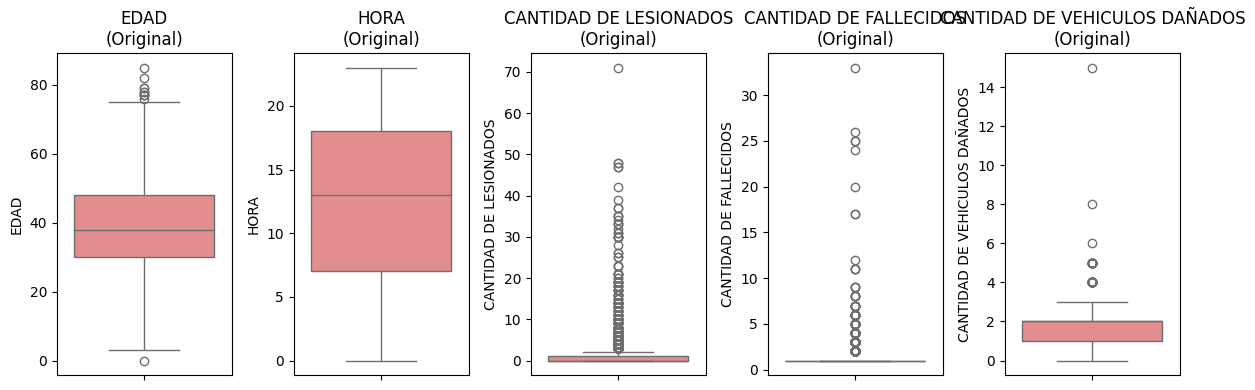


--- Resultados de la eliminación ---
Registros eliminados en total: 1239 (28.81%)
Registros restantes: 3061


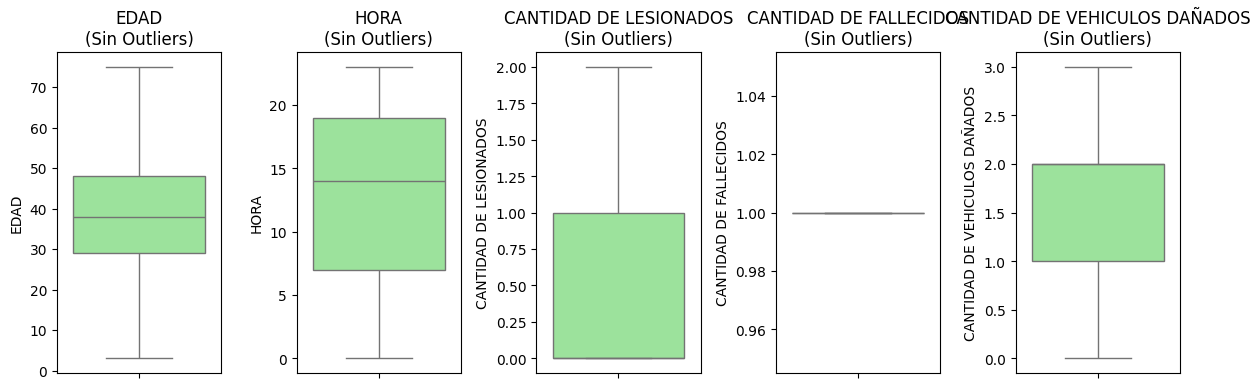

(3061, 119)


In [ ]:
df = cargar_datos()
df = filtrar_eliminar(df)
df = convertir_estado_licencia(df)
df = convertir_gravedad_bin(df)
df = convertir_datos(df)
columnas_a_limpiar = ['EDAD',"HORA","CANTIDAD DE LESIONADOS","CANTIDAD DE FALLECIDOS","CANTIDAD DE VEHICULOS DAÑADOS"]
df = gestionar_outliers(df, columnas_a_limpiar, eliminar=True)
X, y = preparar_one_hot(df)
#X = X.drop(columns=["ESTADO LICENCIA_VIGENTE", "CAUSA ESPECÍFICA_CRUCE INDEBIDO POR LA CALZADA", "SUPERFICIE DE CALZADA_AFIRMADO"])
print(X.shape)

=== TOP 10 CORRELACIONES NEGATIVAS CON FALLECIDO ===
POSEE LICENCIA_SI                                -0.259042
ESTADO LICENCIA_VIGENTE                          -0.213861
CAUSA FACTOR PRINCIPAL_IMPRUDENCIA DEL PEATÓN    -0.167308
VEHÍCULO_ÓMNIBUS                                 -0.134313
VEHÍCULO_CAMIONETA RURAL                         -0.130410
CAUSA ESPECÍFICA_CRUCE INDEBIDO POR LA CALZADA   -0.125937
SUPERFICIE DE CALZADA_ASFALTADA                  -0.113929
VEHÍCULO_REMOLCADOR-SEMIREMOLQUE                 -0.109857
VEHÍCULO_CAMIÓN                                  -0.107429
CARACTERÍSTICAS DE VÍA_TRAMO RECTO               -0.097050
Name: FALLECIDO, dtype: float64

=== TOP 10 CORRELACIONES POSITIVAS CON FALLECIDO ===
VEHÍCULO_MOTOCICLETA                                0.421527
CLASE SINIESTRO_DESPISTE                            0.313633
VEHÍCULO_TRIMOTO PASAJERO                           0.120211
CLASE SINIESTRO_VOLCADURA                           0.103761
CAUSA ESPECÍFICA_FATIGA Y/O

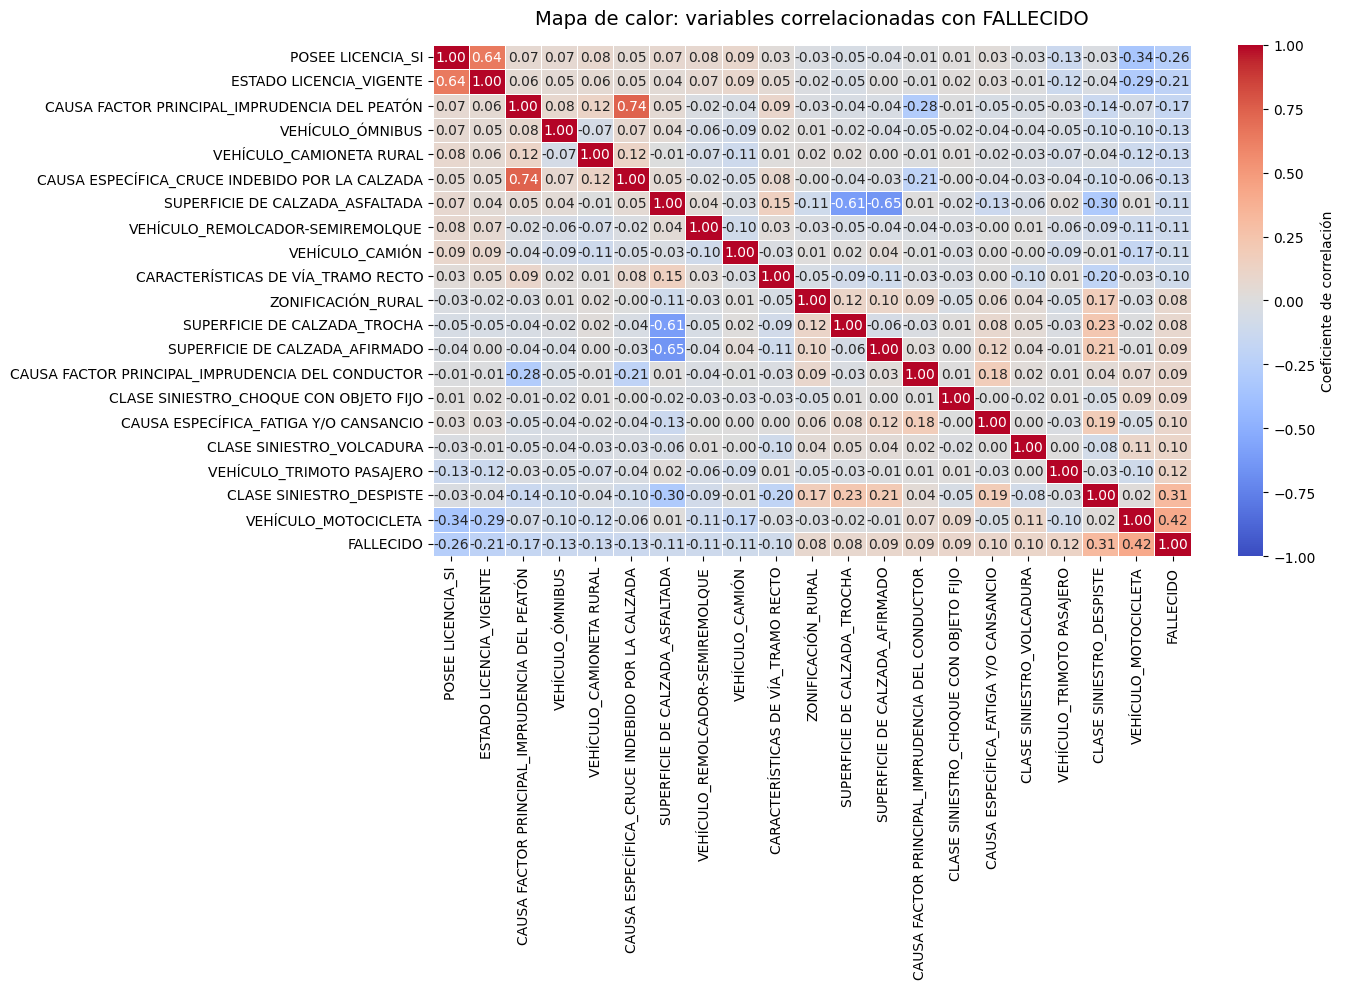

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def analizar_correlacion(
    X,
    y,
    target_name="TARGET_GRAVEDAD",
    top_n=8
):
    # 1. Asegurar que X sea un DataFrame de pandas
    X_cpu = X.copy() if isinstance(X, pd.DataFrame) else pd.DataFrame(X)

    # 2. Convertir y a una Serie de pandas
    if isinstance(y, pd.Series):
        y_cpu = y.reindex(X_cpu.index)
    else:
        y_cpu = pd.Series(y, index=X_cpu.index)

    # 3. Convertir el target a valores numéricos
    y_cpu = pd.to_numeric(y_cpu, errors="coerce")

    # 4. Construir el DataFrame temporal
    df = X_cpu.copy()
    df[target_name] = y_cpu

    # 5. Seleccionar únicamente columnas numéricas y booleanas
    df = df.select_dtypes(include=["number", "bool"])

    # 6. Calcular la matriz de correlación usando pandas
    correlaciones = (
        df.corr()[target_name]
        .drop(labels=[target_name])
        .dropna()
        .sort_values()
    )

    # 7. Mostrar las correlaciones negativas
    print(
        f"=== TOP {top_n} CORRELACIONES NEGATIVAS "
        f"CON {target_name} ==="
    )
    print(correlaciones.head(top_n))

    # 8. Mostrar las correlaciones positivas
    print(
        f"\n=== TOP {top_n} CORRELACIONES POSITIVAS "
        f"CON {target_name} ==="
    )
    print(
        correlaciones.tail(top_n)
        .sort_values(ascending=False)
    )

    # 9. Seleccionar las variables más destacadas
    top_negativas = correlaciones.head(top_n).index.tolist()
    top_positivas = correlaciones.tail(top_n).index.tolist()

    variables_destacadas = list(dict.fromkeys(
        top_negativas + top_positivas + [target_name]
    ))

    # 10. Calcular la matriz de correlación reducida
    matriz = df[variables_destacadas].corr()

    # 11. Graficar el mapa de calor
    plt.figure(figsize=(14, 10))

    sns.heatmap(
        matriz,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        vmin=-1,
        vmax=1,
        center=0,
        linewidths=0.5,
        cbar_kws={
            "label": "Coeficiente de correlación"
        }
    )

    plt.title(
        f"Mapa de calor: variables correlacionadas con {target_name}",
        fontsize=14,
        pad=15
    )

    plt.tight_layout()
    plt.show()


# Ejecutar
analizar_correlacion(
    X,
    y,
    target_name="FALLECIDO",
    top_n=10
)